# Compare F.E. Walter reservoir operations

Start with the saved results from all three January 1–7, 2021 simulations. Then use **Run All** from your clone to reproduce the Rule-based baseline offline. The last section lets you make new Ollama runs for both LLM cases.

## Saved comparison

All three runs used the same seven days of the public F.E. Walter study inputs. The two LLM cases ran on Ollama 0.40.6 with `gemma4:12b` (Q4_K_M), seed 3, temperature 0.7, and 2,048 maximum output tokens per request. Each LLM case made seven requests. The Rule-based run made zero.

The model manifest SHA-256 was `4eb23ef187e2c5462566d6a1d3bbbc2f1346d0b4327cbb66d58fffbcc9b2b05c`. The public experiment settings came from commit `c2312b5f`. All three runs passed output verification.

In [1]:
from io import StringIO

import matplotlib.pyplot as plt
import pandas as pd

reference_csv = """
date,inflow_cms,rule_release,rule_storage,without_release,without_storage,with_release,with_storage
2021-01-01,10.670071982241376,8.459752801833018,4528362.503597423,10.670071982241376,4337390.926410141,10.670071982241376,4337390.926410141
2021-01-02,8.77246894312245,6.982303634386102,4683032.7862722445,1.41584235,4973003.464055921,8.77246894312245,4337390.926410141
2021-01-03,7.822622538884147,6.2427655169746155,4819532.432965228,1.41584235,5526549.272375511,7.822622538884147,4337390.926410141
2021-01-04,7.334458992984942,5.862687697958478,4946693.472855515,1.41584235,6037917.75032941,7.334458992984942,4337390.926410141
2021-01-05,7.069910568828609,5.656713718700601,5068793.6807065755,1.41584235,6526429.244436202,7.069910568828609,4337390.926410142
2021-01-06,6.913459323093393,5.534902803565868,5187900.963993753,1.41584235,7001423.35091147,6.913459323093393,4337390.926410142
2021-01-07,6.809299974880447,5.453805683079339,5305015.670805369,1.41584235,7467418.08970114,6.809299974880447,4337390.926410142
"""
reference_daily = pd.read_csv(StringIO(reference_csv.strip()), parse_dates=["date"])
reference_cases = {
    "Rule-based": ("rule", 0),
    "Without operational knowledge": ("without", 7),
    "With operational knowledge": ("with", 7),
}
reference_runs = {}
reference_metrics = []
for name, (prefix, calls) in reference_cases.items():
    daily = reference_daily[["date", "inflow_cms", f"{prefix}_release", f"{prefix}_storage"]].rename(
        columns={f"{prefix}_release": "controlled_release_cms", f"{prefix}_storage": "storage_end_m3"}
    )
    reference_runs[name] = {"trajectory": daily}
    reference_metrics.append({
        "Case": name,
        "Mean controlled release (m³/s)": daily["controlled_release_cms"].mean(),
        "Jan 7 storage (million m³)": daily["storage_end_m3"].iloc[-1] / 1_000_000,
        "Ollama requests": calls,
    })
pd.DataFrame(reference_metrics).set_index("Case").round(3)

,Mean controlled release (m³/s),Jan 7 storage (million m³),Ollama requests
Case,,,
Rule-based,6.313,5.305,0
Without operational knowledge,2.738,7.467,7
With operational knowledge,7.913,4.337,7


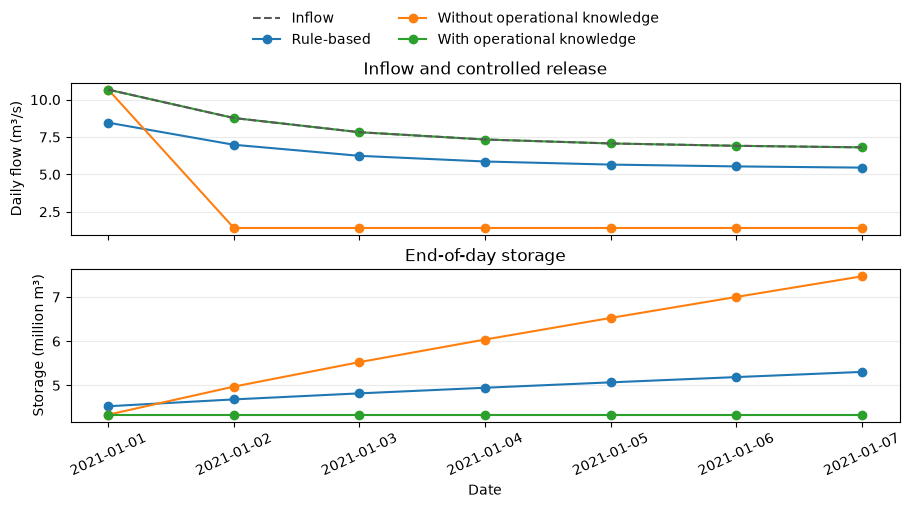

In [2]:
def plot_results(runs):
    figure, (flow_axis, storage_axis) = plt.subplots(2, 1, sharex=True, figsize=(9, 5), layout="constrained")
    inflow = runs["Rule-based"]["trajectory"]
    flow_axis.plot(inflow["date"], inflow["inflow_cms"], color="0.35", linestyle="--", label="Inflow", zorder=4)
    for name, run in runs.items():
        daily = run["trajectory"]
        flow_axis.plot(daily["date"], daily["controlled_release_cms"], marker="o", label=name)
        storage_axis.plot(daily["date"], daily["storage_end_m3"] / 1_000_000, marker="o", label=name)
    flow_axis.set(ylabel="Daily flow (m³/s)", title="Inflow and controlled release")
    storage_axis.set(ylabel="Storage (million m³)", xlabel="Date", title="End-of-day storage")
    figure.legend(*flow_axis.get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False)
    for axis in (flow_axis, storage_axis):
        axis.grid(axis="y", alpha=0.25)
    storage_axis.tick_params(axis="x", labelrotation=25)
    return figure

preview_figure = plot_results(reference_runs)
plt.show()

Read the controlled release against inflow in the upper panel and the daily storage below. In these saved runs, With operational knowledge released close to the incoming flow and ended near the shared starting storage. Without operational knowledge released less and stored more water during this seven-day window.

## 1. Reproduce the Rule-based run

The Hanasaki rule uses the shared F.E. Walter inflow and reservoir settings. Each execution writes a new verified run in a local temporary directory, whose path appears below. The daily table lists controlled release and spill separately.

In [ ]:
from pathlib import Path
from shutil import copytree
from tempfile import mkdtemp

import yaml

from llm_reservoir_agent.verification import verify_run
from llm_reservoir_agent.workflow import load_settings, run_settings

root = Path.cwd()
if root.name == "tutorials":
    root = root.parent
example_dir = root / "examples" / "fe_walter"
if not (example_dir / "rule_based.yaml").is_file():
    raise FileNotFoundError("Open the notebook from the HydroReOpLLM checkout or its tutorials directory.")

config_paths = {
    "Rule-based": example_dir / "rule_based.yaml",
    "Without operational knowledge": example_dir / "seasonal_target.yaml",
    "With operational knowledge": example_dir / "dkp.yaml",
}


def run_case(name, *, allow_network=False):
    run_root = Path(mkdtemp(prefix="hydroreopllm-walter-"))
    case_copy = run_root / "examples" / "fe_walter"
    copytree(example_dir, case_copy)
    settings = load_settings(case_copy / config_paths[name].name)
    output = Path(settings.report["output"])
    print(f"{name} outputs: {output}")
    run_settings(settings, allow_network=allow_network)
    verification = verify_run(output, require_offline=not allow_network)
    trajectory = pd.read_csv(output / "reservoir_trajectory.csv", parse_dates=["date"])
    return {"trajectory": trajectory, "verification": verification, "output": output}

In [ ]:
baseline = run_case("Rule-based")
proof = baseline["verification"]
print(f"Verification {proof['status']} | {proof['days']} days | {proof['observed_network_calls']} network calls")
print(f"Maximum water balance residual: {proof['max_system_balance_residual_m3']:.3g} m³")

columns = {
    "date": "Date",
    "inflow_cms": "Inflow (m³/s)",
    "controlled_release_cms": "Controlled release (m³/s)",
    "spill_cms": "Spill (m³/s)",
    "storage_end_m3": "End storage (m³)",
}
daily_table = baseline["trajectory"][list(columns)].copy()
daily_table["date"] = daily_table["date"].dt.strftime("%Y-%m-%d")
daily_table.round(2).rename(columns=columns)

## 2. Inspect the two prompt configurations

Both cases use the same seven study dates, reservoir, inflow, seasonal targets, and model profile. **With operational knowledge** also loads the local operating guidance. The table lists each prompt file and the planned number of decisions. The check reads the setup offline without making model requests.

In [ ]:
check_results = {name: load_settings(path).report for name, path in config_paths.items()}
comparison = {}
for name in ("Without operational knowledge", "With operational knowledge"):
    config = yaml.safe_load(config_paths[name].read_text(encoding="utf-8"))
    operator = config["agents"]["walter_operator"]
    comparison[name] = {
        "System prompt": operator["prompt"]["system"],
        "Daily prompt": operator["prompt"]["user"],
        "Operating guidance": ", ".join(operator.get("knowledge", {}).values()),
        "Planned decisions": check_results[name]["planned_llm_calls"],
    }

pd.DataFrame.from_dict(comparison, orient="index")

## 3. Optionally make two new Ollama runs

Start local Ollama with `gemma4:12b`. Set `RUN_LLM` to `True` and run the next two cells. The two YAMLs point to the local Ollama endpoint and allow up to 14 requests per case, including retries. Restore `False` before using Run All for an offline run.

If you run both cases, compare their release and storage lines against the shared inflow and the Rule-based baseline. These seven-day runs use the public prompts and simulator. Use the [results guide](../docs/RESULTS_GUIDE.md) to inspect the verified output, daily decisions, and provider attempts.

In [ ]:
RUN_LLM = False

In [ ]:
llm_runs = {}
if RUN_LLM:
    for name in comparison:
        llm_runs[name] = run_case(name, allow_network=True)
        verification = llm_runs[name]["verification"]
        print(f"Verification {verification['status']} | {verification['days']} days | {verification['observed_network_calls']} network calls")
    comparison_figure = plot_results({"Rule-based": baseline, **llm_runs})
    plt.show()
else:
    print("Run All completed the offline baseline. Enable RUN_LLM above to compare the two Ollama runs.")